# Which augments actually win?
## De-inflating Tencent's Mayhem augment statistics, then ranking what is left

**Question.** DeepARAM shows Tencent's official ARAM Mayhem augment stats for the China server: BEES!!! wins 70.7% of its games, King Me 37.0%. Which augments *actually* raise a player's win rate, once small samples are shrunk and the champions who pick them are controlled for?

**What the data turned out to say first.** Before any of that, the numbers themselves need decoding. A plain sample of augment picks has to average 50%, but Tencent's augment win rates average **54.4%** weighted by pick rate, and no augment taken in more than a quarter of games wins less than 53%. This notebook shows that the published augment `pick_rate` and `win_rate` are **game-level** statistics (the share of games in which *someone* took the augment, and the share of those games won by a team that had it), which mechanically inflates popular augments. Working out that mechanism gives a closed-form correction with no fitted parameters, after which the whole feed is internally consistent (the pick-weighted mean becomes 50.3%).

**Data.** `data/cn/augments.json` (214 augments: win rate, pick rate, tier, 2026-10-28, patch 16.21), `data/cn/builds/<id>.json` (173 champions x their most-taken augments: per-champion pick share and Tencent's S/A/B/C grade), `data/cn/champions.json` (baseline win and pick rates), the daily augment snapshots in `data/cn/history/augments/` (two patch windows, 16.20 and 16.21), and `simulator/data/augments.json` / `augment_pools.json` for names, rarities and which champions can be offered each augment. Tencent publishes no sample sizes.

**TL;DR**

1. The augment feed is **not a sample of picks**. Three checks (pick-rate algebra, the 54% mean, a rising lower envelope) all say the published rates are per *game*, not per pick. The correction `team win rate = published win rate x (1 - q/2)`, with `q = 1 - sqrt(1 - pick_rate)` the chance a given team has the augment, removes the artifact exactly under that model.
2. After correction the spread of augment effects is **about +-5 pp, not +-20 pp**. BEES!!! goes from +20.7 to **+3.9 pp**; the "59% win rate" augments Recursion and Shrink Engine are within a point of neutral. The top five by corrected, shrunk, composition-adjusted uplift are Draw Your Sword (+8.8), Windspeaker's Blessing (+7.0), Armored Impact (+5.7), Weapon of Destiny (+4.7) and Infinite Recursion (+4.1); the bottom is King Me (**-13.2**), Brass Blast (-4.7) and Glass Cannon (-4.6).
3. **Who picks an augment barely matters** (the champion-mix adjustment moves win rates by at most 1.7 pp, SD 0.5 pp), and **sampling noise barely matters** either: the implied volume puts even the rarest augment within +-1 pp, and the corrected ranking replicates across two patch windows at r = 0.95. Empirical-Bayes shrinkage moves only the four augments taken in under 1% of games.
4. **Tier is not strength.** The mean corrected uplift is within 0.5 pp of zero for Prismatic, Gold and Silver alike; Prismatic merely has the widest spread (its two tails are Draw Your Sword and King Me).
5. Players still **chase winners**: the Spearman correlation between pick rate and corrected uplift is 0.27 (0.73 before correction), so the selection story survives but is much smaller than the raw numbers suggest. The most champion-specific augments (graded S on some champions and C on others) are kit-dependent ones such as Dual Wield, Heavy Hitter, Steel Your Heart and Wooglet's Witchcap; the most universal are the flat stat buys (Mad Scientist, the Souls, Apex Inventor).

## 1. Setup and data

Everything runs offline from files in this repository. The notebook finds the repo root by walking up from its own folder. The palette and axis style follow the sibling notebook in `analysis/win-rate-persistence/`.

In [1]:
from pathlib import Path
import glob, json, warnings
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.formula.api as smf
import matplotlib as mpl
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "cn" / "builds").exists():
    ROOT = ROOT.parent
FIG = ROOT / "analysis" / "augment-uplift"
CN = ROOT / "data" / "cn"

PAL = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "violet": "#6250d6",
     "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e4e3df", "surface": "#fcfcfb", "mute": "#b9b7b2"}
TIER = {"Prismatic": PAL["violet"], "Gold": PAL["orange"], "Silver": PAL["blue"]}
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": PAL["surface"], "axes.facecolor": PAL["surface"],
    "axes.edgecolor": PAL["ink2"], "axes.labelcolor": PAL["ink"], "axes.titlecolor": PAL["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": PAL["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": PAL["ink2"], "ytick.color": PAL["ink2"], "legend.frameon": False, "font.size": 10,
})
def save(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", facecolor=PAL["surface"])

In [2]:
# Augment-level feed (one row per augment, 2026-10-28, patch 16.21)
raw = json.load(open(CN / "augments.json"))
A = pd.DataFrame(raw["augments"])
sim = json.load(open(ROOT / "simulator" / "data" / "augments.json"))["augments"]
NAME = {v["id"]: v["name"] for v in sim.values()}
SLUG = {v["id"]: k for k, v in sim.items()}
A["name"] = A.augment_id.map(NAME)
A["slug"] = A.augment_id.map(SLUG)

# Champion-level feed: baseline win rate B and pick rate g (share of games the champion appears in; sums to 10 slots)
champs = pd.DataFrame(json.load(open(CN / "champions.json"))["champions"])
CH = champs[["champion_id", "win_rate", "pick_rate"]].rename(columns={"win_rate": "B", "pick_rate": "g"})
CNAME = {}

# Champion x augment feed: per-champion pick share p (share of the champion's games in which the augment was taken) and grade
rows = []
for f in sorted(glob.glob(str(CN / "builds" / "*.json"))):
    if f.endswith("index.json"):
        continue
    d = json.load(open(f))
    CNAME[d["id"]] = d["name"]
    for x in d["augments"]["all"]:
        rows.append((d["id"], x["id"], x["pick_rate"], x["grade"]))
L = pd.DataFrame(rows, columns=["champion_id", "augment_id", "p", "grade"]).merge(CH, on="champion_id")
L["w"] = L.g * L.p            # expected players per game who are this champion AND take this augment

# Pools: which champions can be offered each augment
pools = json.load(open(ROOT / "simulator" / "data" / "augment_pools.json"))["pools"]
pool_ids = {int(c): {sim[s]["id"] for s in v} for c, v in pools.items()}

print(f"{len(A)} augments with stats ({A.tier.value_counts().to_dict()}), {len(raw['no_data'])} live augments without stats")
print(f"{L.champion_id.nunique()} champions x {L.groupby('champion_id').size().mean():.0f} listed augments on average = {len(L)} champion-augment rows")
print(f"Sum of augment pick rates: {A.pick_rate.sum():.1f}   sum of champion pick rates: {CH.g.sum():.2f}   per-champion augment shares sum to {L.groupby('champion_id').p.sum().mean():.2f}")
A[["name", "tier", "win_rate", "pick_rate"]].sort_values("win_rate", ascending=False).head(8).reset_index(drop=True)

214 augments with stats ({'Gold': 83, 'Silver': 66, 'Prismatic': 65}), 26 live augments without stats
173 champions x 122 listed augments on average = 21031 champion-augment rows
Sum of augment pick rates: 37.1   sum of champion pick rates: 10.00   per-champion augment shares sum to 3.67


,name,tier,win_rate,pick_rate
0,BEES!!!,Gold,0.7071,0.7264
1,Transmute: Prismatic,Gold,0.6332,0.6097
2,Armored Impact,Gold,0.6306,0.4057
3,Weapon of Destiny,Gold,0.6224,0.4273
4,The Boom and the Bass,Gold,0.6141,0.4139
5,Draw Your Sword,Prismatic,0.6034,0.1540
6,Infinite Recursion,Prismatic,0.6020,0.3601
7,Take'em Down Down Down,Gold,0.5992,0.4213


The three sums are the first clue to what the rates mean. Champion pick rates sum to 10 (ten players, each a share of games), per-champion augment shares sum to about 3.7 (close to the four augment levels in a Mayhem game, less the games that end early and the long tail of augments the builds page truncates), and the 214 augment pick rates sum to 37. Read naively, 37 = 10 players x 3.7 augments, so `pick_rate` would be the expected number of players per game taking the augment. That reading is wrong, and Section 2 shows why.

## 2. What do the published numbers mean?

### 2.1 The 54% problem

Every pick is made by exactly one player, and exactly half of all players win. So if `win_rate` were the share of picks that won and `pick_rate` were proportional to the number of picks, the pick-weighted mean win rate would be 50% by construction. The other three feeds Tencent publishes pass this test. The augment feed fails it.

In [3]:
def wmean(w, x):
    return float((w * x).sum() / w.sum())

checks = {"Champions (champions.json)": wmean(CH.g, CH.B)}
sk, it, st = [], [], []
for f in glob.glob(str(CN / "builds" / "*.json")):
    if f.endswith("index.json"):
        continue
    d = json.load(open(f))
    for key, store in (("skills", sk), ("other", it)):
        src = d["skills"] if key == "skills" else d["items"]["other"]
        store.append((d["id"], sum(x["pick_rate"] for x in src), sum(x["pick_rate"] * x["win_rate"] for x in src)))
for label, store in (("Skill orders (builds/*.json)", sk), ("Items (builds/*.json, 'other')", it)):
    t = pd.DataFrame(store, columns=["cid", "s", "sw"]).merge(CH, left_on="cid", right_on="champion_id")
    checks[label] = wmean(t.g * t.s, t.sw / t.s)
checks["Augments (augments.json)"] = wmean(A.pick_rate, A.win_rate)
for t, g in A.groupby("tier"):
    checks[f"   {t} augments only"] = wmean(g.pick_rate, g.win_rate)
pd.Series(checks, name="pick-weighted mean win rate").to_frame().style.format("{:.1%}")

,pick-weighted mean win rate
Champions (champions.json),50.0%
Skill orders (builds/*.json),50.0%
"Items (builds/*.json, 'other')",49.9%
Augments (augments.json),54.4%
Gold augments only,55.5%
Prismatic augments only,53.7%
Silver augments only,53.7%


Champions, skill orders and items all average 50.0% (items within rounding of the champion baselines, 49.5%). Augments average 54.4%, and every tier is above 53%. Either the published pick rate is not proportional to picks, or the win rate is not a share of picks, or both.

### 2.2 Pick rate: per pick or per game?

The builds feed gives an independent route to each augment's volume: summing `champion pick rate x per-champion augment share` over champions gives the expected number of players per game who take it (call it `implied`). If the global `pick_rate` counted picks, it would equal `implied` (a little above it, because the builds lists are truncated at 93 to 157 augments per champion). If instead it counted **games in which at least one player took the augment**, it would equal `1 - (1 - implied/10)^10`, which bends below `implied` for popular augments. The truncation can only push `implied` *down*, so any augment where the reported rate falls *below* `implied` is evidence for the game-level reading.

In [4]:
A["implied"] = A.augment_id.map(L.groupby("augment_id").w.sum())
A["pred_game"] = 1 - (1 - A.implied / 10) ** 10
out = []
for lo in (0.0, 0.15, 0.3, 0.5):
    h = A[A.implied > lo]
    out.append({"implied players/game >": lo, "augments": len(h),
                "MAE if per pick": np.abs(h.implied - h.pick_rate).mean(),
                "MAE if per game": np.abs(h.pred_game - h.pick_rate).mean(),
                "mean error, per pick": (h.pick_rate - h.implied).mean(),
                "mean error, per game": (h.pick_rate - h.pred_game).mean()})
pd.DataFrame(out).set_index("implied players/game >").style.format("{:.3f}")

,augments,MAE if per pick,MAE if per game,"mean error, per pick","mean error, per game"
implied players/game >,,,,,
0.000000,214.000,0.024,0.023,0.002,0.023
0.150000,91.000,0.040,0.034,-0.012,0.034
0.300000,32.000,0.070,0.039,-0.053,0.038
0.500000,7.000,0.164,0.031,-0.164,0.028


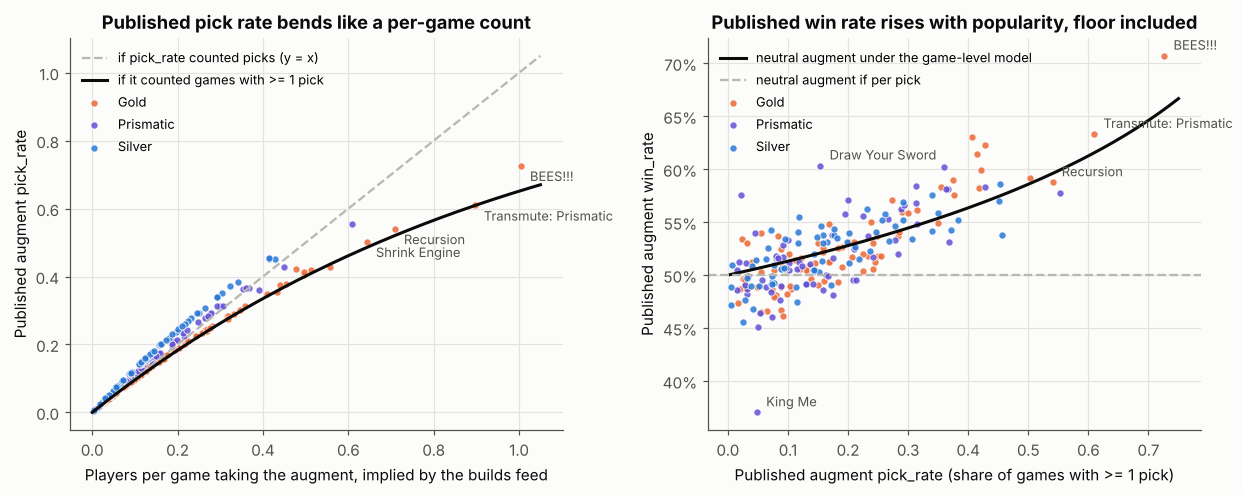

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
ax = axes[0]
xx = np.linspace(0, 1.05, 200)
ax.plot(xx, xx, color=PAL["mute"], lw=1.5, ls="--", label="if pick_rate counted picks (y = x)")
ax.plot(xx, 1 - (1 - xx / 10) ** 10, color=PAL["ink"], lw=2, label="if it counted games with >= 1 pick")
for t, g in A.groupby("tier"):
    ax.scatter(g.implied, g.pick_rate, s=22, color=TIER[t], alpha=0.85, edgecolor=PAL["surface"], lw=0.6, label=t)
for _, r in A.nlargest(4, "implied").iterrows():
    ax.annotate(r["name"], (r.implied, r.pick_rate), xytext=(6, -10), textcoords="offset points", fontsize=8.5, color=PAL["ink2"])
ax.set_xlabel("Players per game taking the augment, implied by the builds feed")
ax.set_ylabel("Published augment pick_rate")
ax.set_title("Published pick rate bends like a per-game count")
ax.legend(loc="upper left", fontsize=8.5)

ax = axes[1]
A["q"] = 1 - np.sqrt(1 - A.pick_rate)            # P(a given team has the augment), from the per-game rate
A["null_wr"] = 1 / (2 - A.q)                       # published win rate of a neutral augment under the game-level model
xx = np.linspace(0.004, 0.75, 200)
ax.plot(xx, 1 / (1 + np.sqrt(1 - xx)), color=PAL["ink"], lw=2, label="neutral augment under the game-level model")
ax.axhline(0.5, color=PAL["mute"], lw=1.5, ls="--", label="neutral augment if per pick")
for t, g in A.groupby("tier"):
    ax.scatter(g.pick_rate, g.win_rate, s=22, color=TIER[t], alpha=0.85, edgecolor=PAL["surface"], lw=0.6, label=t)
for nm in ["BEES!!!", "King Me", "Recursion", "Transmute: Prismatic", "Draw Your Sword"]:
    r = A[A.name == nm].iloc[0]
    ax.annotate(nm, (r.pick_rate, r.win_rate), xytext=(6, 4), textcoords="offset points", fontsize=8.5, color=PAL["ink2"])
ax.set_xlabel("Published augment pick_rate (share of games with >= 1 pick)")
ax.set_ylabel("Published augment win_rate")
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_title("Published win rate rises with popularity, floor included")
ax.legend(loc="upper left", fontsize=8.5)
fig.tight_layout(); save(fig, "fig1_feed_decoding.png"); plt.show()

For the seven augments taken by more than half a player per game, the per-game model is five times closer (mean absolute error 0.031 vs 0.164), and the per-pick model's error is all one-signed. The right panel shows the consequence for win rates: the *lowest* win rate in each popularity band rises with pick rate, tracking the black curve, which is what a neutral augment would show if `win_rate` is **the share of games containing the augment that were won by a team that had it**. When both teams have it (likely for popular augments), that game is a "win" whatever happens.

### 2.3 The correction

Let `q` be the probability that a given team has the augment and `w` the probability that a team with it wins (the quantity we actually want; for a neutral augment `w = 0.5`). Treating the two teams as independent draws:

- share of games with the augment anywhere: `pick_rate = 1 - (1 - q)^2`, so `q = 1 - sqrt(1 - pick_rate)`;
- share of those games won by a team that had it: `win_rate = 2 q w / (2q - q^2) = w / (1 - q/2)`.

So `w = win_rate x (1 - q/2)`. No parameters are fitted. The site's current fix (`web/src/lib/augment-winrate.ts`) regresses win rate on pick rate within each rarity and removes the slope; that also removes any *real* tendency for good augments to be picked more, and it re-centres each rarity on 50% by assumption. The closed form only removes the arithmetic.

In [6]:
A["w"] = A.win_rate * (1 - A.q / 2)
print(f"Pick-weighted mean of published win rate: {wmean(A.pick_rate, A.win_rate):.1%}")
print(f"Team-games-weighted mean of corrected team win rate: {wmean(A.q, A.w):.1%}   (a sample of team-games must average 50%)")
A["pb"] = pd.qcut(A.pick_rate, 6, labels=False)
env = A.groupby("pb").agg(pick_rate=("pick_rate", "mean"), published_min=("win_rate", "min"), published_median=("win_rate", "median"),
                          corrected_min=("w", "min"), corrected_median=("w", "median"))
env.index = [f"band {i+1}" for i in env.index]
env.style.format({"pick_rate": "{:.3f}", "published_min": "{:.1%}", "published_median": "{:.1%}", "corrected_min": "{:.1%}", "corrected_median": "{:.1%}"})

Pick-weighted mean of published win rate: 54.4%
Team-games-weighted mean of corrected team win rate: 50.3%   (a sample of team-games must average 50%)


,pick_rate,published_min,published_median,corrected_min,corrected_median
band 1,0.031,37.0%,49.0%,36.6%,48.7%
band 2,0.078,46.0%,49.7%,45.1%,48.9%
band 3,0.119,47.4%,50.6%,46.0%,49.2%
band 4,0.172,48.1%,52.6%,45.9%,50.2%
band 5,0.246,49.5%,53.1%,46.7%,49.6%
band 6,0.396,53.1%,57.7%,46.7%,51.3%


The corrected feed passes the test the published one failed (50.3%, the residual being the independence approximation and the truncated tail), and the floor is flat: the worst augment in every popularity band now sits at 45 to 47%.

## 3. Who picks it: the champion-mix adjustment

An augment picked mostly by Lillia (57.6% baseline) would look good even if it did nothing. The builds feed gives each augment's picker mix, so its **expected** win rate from composition alone is `E = sum_c g_c p_ac B_c / sum_c g_c p_ac`. The **uplift** is `w - E`. (Comparing `w` to `E` is apples to apples: a champion's published win rate is the win rate of the team it is on.)

In [7]:
E = L.groupby("augment_id").apply(lambda t: (t.w * t.B).sum() / t.w.sum())
A["E"] = A.augment_id.map(E)
A["n_pickers"] = A.augment_id.map(L.groupby("augment_id").size())
A["uplift"] = A.w - A.E
A["uplift_published"] = A.win_rate - 0.5
print(f"Composition-expected win rate E: mean {A.E.mean():.1%}, SD {A.E.std()*100:.2f} pp, range {A.E.min():.1%} to {A.E.max():.1%}")
print(f"Corrected team win rate w:       SD {A.w.std()*100:.2f} pp, range {A.w.min():.1%} to {A.w.max():.1%}")
print(f"Published win rate:              SD {A.win_rate.std()*100:.2f} pp, range {A.win_rate.min():.1%} to {A.win_rate.max():.1%}")
print(f"Spearman(published, corrected uplift) = {stats.spearmanr(A.win_rate, A.uplift)[0]:.2f}")
ext = A.loc[A.E.abs().sub(0.5).abs().nlargest(4).index, ["name", "tier", "E", "w", "uplift"]]
ext.style.format({"E": "{:.1%}", "w": "{:.1%}", "uplift": "{:+.1%}"}).hide(axis="index")

Composition-expected win rate E: mean 49.9%, SD 0.51 pp, range 48.5% to 51.7%
Corrected team win rate w:       SD 2.38 pp, range 36.6% to 57.9%
Published win rate:              SD 3.83 pp, range 37.0% to 70.7%
Spearman(published, corrected uplift) = 0.80


name,tier,E,w,uplift
Mystic Punch,Prismatic,51.7%,52.0%,+0.3%
Upgrade Sword of Blossoming Dawn,Prismatic,48.5%,48.4%,-0.0%
Outlaw's Grit,Gold,51.5%,52.5%,+1.0%
Hands off the Talent,Silver,48.6%,46.0%,-2.5%


The champion mix is worth at most 1.7 pp either way (Mystic Punch and Outlaw's Grit draw strong pickers; Upgrade Sword of Blossoming Dawn and Hands off the Talent draw weak ones). Against a 4 pp spread in corrected win rates it is a second-order correction, which is itself a finding: ARAM's random champion assignment and the broad pools keep picker composition close to the population. The composition term is kept in `uplift` anyway.

## 4. Sampling noise and shrinkage

Tencent publishes no counts, so volume has to be inferred. The sibling notebook's split-half analysis of the champion feed implies at least ~80,000 Mayhem games per day on this server. The 16.21 window here is 7 days, so each augment has roughly `2 x q x 560,000` team-games behind its win rate, and a binomial standard error follows. That gives empirical-Bayes shrinkage toward the tier mean with weight `tau^2 / (tau^2 + se^2)`, where `tau^2` is the between-augment variance within the tier net of sampling variance.

In [8]:
GAMES_PER_DAY, DAYS = 80_000, 7
A["n_team_games"] = 2 * A.q * GAMES_PER_DAY * DAYS
A["se"] = np.sqrt(0.25 / A.n_team_games)
shr = []
for t, g in A.groupby("tier"):
    tau2 = max(g.uplift.var() - (g.se ** 2).mean(), 1e-6)
    k = tau2 / (tau2 + g.se ** 2)
    shr.append(pd.DataFrame({"augment_id": g.augment_id, "shrunk": g.uplift.mean() + k * (g.uplift - g.uplift.mean()), "k": k}))
A = A.merge(pd.concat(shr), on="augment_id")
A["rank_raw"] = A.uplift.rank(ascending=False).astype(int)
A["rank_shrunk"] = A.shrunk.rank(ascending=False).astype(int)
moved = A.assign(dr=(A.rank_raw - A.rank_shrunk).abs()).nlargest(6, "dr")
print(f"Median standard error {A.se.median()*100:.2f} pp; largest {A.se.max()*100:.2f} pp ({A.loc[A.se.idxmax(), 'name']}, pick_rate {A.pick_rate.min():.4f})")
print(f"Shrinkage weight k: median {A.k.median():.3f}, minimum {A.k.min():.3f}; rank changes of 3+ places: {(np.abs(A.rank_raw - A.rank_shrunk) >= 3).sum()} of {len(A)}")
moved[["name", "tier", "pick_rate", "uplift", "shrunk", "k", "rank_raw", "rank_shrunk"]].style.format({"pick_rate": "{:.4f}", "uplift": "{:+.1%}", "shrunk": "{:+.1%}", "k": "{:.2f}"}).hide(axis="index")

Median standard error 0.17 pp; largest 0.95 pp (Flash 2, pick_rate 0.0049)
Shrinkage weight k: median 0.993, minimum 0.756; rank changes of 3+ places: 4 of 214


name,tier,pick_rate,uplift,shrunk,k,rank_raw,rank_shrunk
Flash 2,Silver,0.0049,-2.4%,-1.9%,0.76,188,173
Sound Barrier,Silver,0.0064,+0.5%,+0.4%,0.80,67,76
Mountain Soul,Silver,0.0377,-1.2%,-1.1%,0.96,147,143
Flashbang,Silver,0.0053,-0.7%,-0.6%,0.77,126,122
Ethereal Weapon,Gold,0.4185,+0.5%,+0.5%,1.00,71,69
First-Aid Kit,Silver,0.0461,+0.7%,+0.7%,0.97,59,61


At this volume shrinkage is cosmetic: it moves only the handful of augments taken in under 1% of games (Flash 2, Flashbang, Sound Barrier). The rest of the analysis uses the shrunk uplift but nothing would change with the raw one.

A direct check uses the previous patch window. `data/cn/history/augments/` holds daily cumulative snapshots for 16.20 (12 to 20 October) and 16.21 (22 to 28 October). Correcting both the same way and comparing the 183 augments present in both windows gives a test-retest estimate that includes any real balance changes, so it is an upper bound on noise.

183 augments in both windows; 31 new in 16.21 (incl. Get Jinxed, Third Times the Harm, Big Shot, Sound Barrier...), 28 rotated out


Test-retest of corrected team win rate: Pearson r = 0.946, Spearman 0.938
Published win rate, for comparison:     Pearson r = 0.962
SD of the patch-to-patch change: 0.84 pp; median binomial SE implied by volume: 0.17 pp
Augments whose change exceeds 3 sampling SDs: 59 of 183 (real change dominates noise, as in the champion feed)


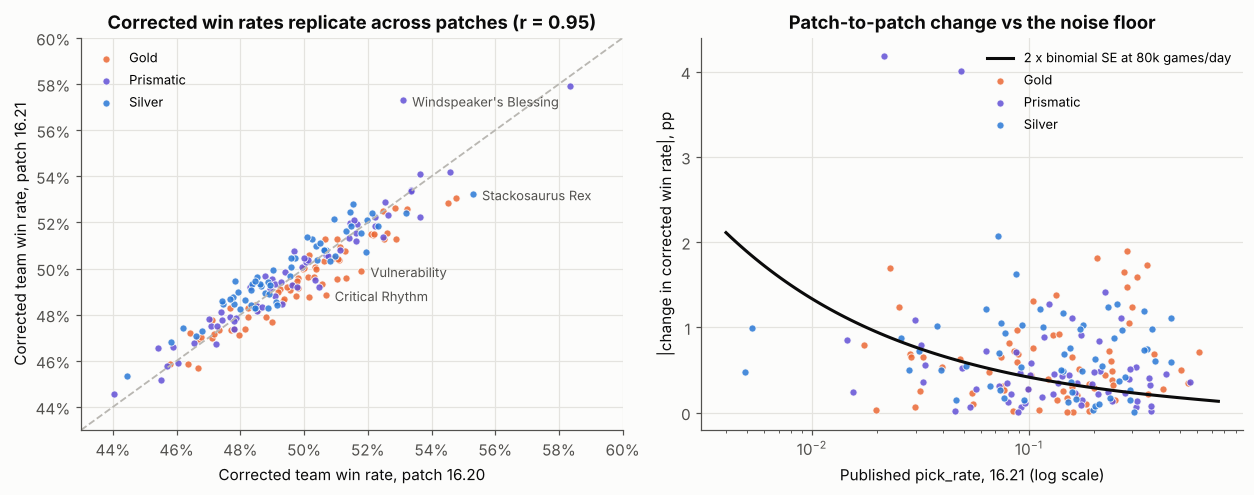

In [9]:
h20 = pd.read_csv(CN / "history" / "augments" / "2026-10-20.csv")
h21 = pd.read_csv(CN / "history" / "augments" / "2026-10-28.csv")
def corrected(h):
    q = 1 - np.sqrt(1 - h.pick_rate)
    return h.assign(q=q, w=h.win_rate * (1 - q / 2))
R = corrected(h20).merge(corrected(h21), on="augment_id", suffixes=("_20", "_21"))
R["name"] = R.augment_id.map(NAME)
R["d"] = R.w_21 - R.w_20
new = sorted(set(h21.augment_id) - set(h20.augment_id)); gone = sorted(set(h20.augment_id) - set(h21.augment_id))
print(f"{len(R)} augments in both windows; {len(new)} new in 16.21 (incl. {', '.join(NAME.get(i, str(i)) for i in new[:4])}...), {len(gone)} rotated out")
print(f"Test-retest of corrected team win rate: Pearson r = {R.w_20.corr(R.w_21):.3f}, Spearman {stats.spearmanr(R.w_20, R.w_21)[0]:.3f}")
print(f"Published win rate, for comparison:     Pearson r = {R.win_rate_20.corr(R.win_rate_21):.3f}")
print(f"SD of the patch-to-patch change: {R.d.std()*100:.2f} pp; median binomial SE implied by volume: {A.se.median()*100:.2f} pp")
R["se_21"] = np.sqrt(0.25 / (2 * R.q_21 * GAMES_PER_DAY * DAYS))
R["se_20"] = np.sqrt(0.25 / (2 * R.q_20 * GAMES_PER_DAY * 9))
R["z"] = R.d / np.sqrt(R.se_20 ** 2 + R.se_21 ** 2)
print(f"Augments whose change exceeds 3 sampling SDs: {(R.z.abs() > 3).sum()} of {len(R)} (real change dominates noise, as in the champion feed)")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
ax = axes[0]
lim = (0.43, 0.60)
ax.plot(lim, lim, color=PAL["mute"], lw=1.2, ls="--")
for t, g in R.groupby("tier_21"):
    ax.scatter(g.w_20, g.w_21, s=22, color=TIER[t], alpha=0.85, edgecolor=PAL["surface"], lw=0.6, label=t)
for _, r in R.assign(ad=R.d.abs()).nlargest(5, "ad").iterrows():
    ax.annotate(r["name"], (r.w_20, r.w_21), xytext=(6, -4), textcoords="offset points", fontsize=8.5, color=PAL["ink2"])
ax.set_xlim(*lim); ax.set_ylim(*lim)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Corrected team win rate, patch 16.20"); ax.set_ylabel("Corrected team win rate, patch 16.21")
ax.set_title(f"Corrected win rates replicate across patches (r = {R.w_20.corr(R.w_21):.2f})")
ax.legend(loc="upper left", fontsize=8.5)
ax = axes[1]
xx = np.logspace(np.log10(0.004), np.log10(0.75), 100)
qq = 1 - np.sqrt(1 - xx)
ax.plot(xx, 2 * np.sqrt(0.25 / (2 * qq * GAMES_PER_DAY * 7)) * 100, color=PAL["ink"], lw=2, label="2 x binomial SE at 80k games/day")
for t, g in R.groupby("tier_21"):
    ax.scatter(g.pick_rate_21, g.d.abs() * 100, s=22, color=TIER[t], alpha=0.85, edgecolor=PAL["surface"], lw=0.6, label=t)
ax.set_xscale("log")
ax.set_xlabel("Published pick_rate, 16.21 (log scale)"); ax.set_ylabel("|change in corrected win rate|, pp")
ax.set_title("Patch-to-patch change vs the noise floor")
ax.legend(loc="upper right", fontsize=8.5)
fig.tight_layout(); save(fig, "fig2_patch_retest.png"); plt.show()

The corrected ranking carries across patches at r = 0.95 even though 16.21 rotated 31 augments in and 28 out and changed balance. A third of the changes exceed three sampling standard deviations, and they do not concentrate among rare augments, so, as with the champion feed, most of what moves between patches is real. One caution for the ranking: Windspeaker's Blessing, second by uplift, is taken in only 2% of games and moved 4 pp between windows, so its place is the least secure in the top ten.

## 5. The ranking

With the mechanics decoded, the question can finally be answered. Figure 3 shows how the top of the published table is rearranged by the correction; the tables list the extremes of the shrunk, composition-adjusted uplift.

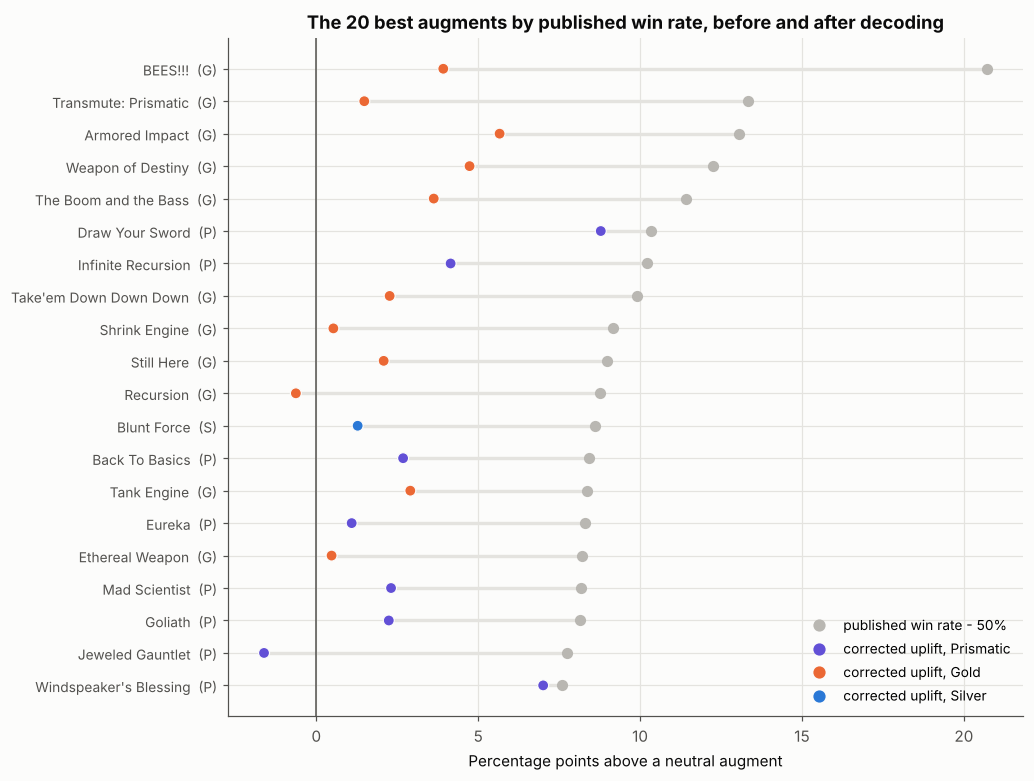

In [10]:
top_pub = A.nlargest(20, "win_rate").sort_values("win_rate")
fig, ax = plt.subplots(figsize=(9.5, 7.2))
y = np.arange(len(top_pub))
for i, (_, r) in enumerate(top_pub.iterrows()):
    ax.plot([r.uplift_published * 100, r.shrunk * 100], [i, i], color=PAL["grid"], lw=2.2, zorder=1)
ax.scatter(top_pub.uplift_published * 100, y, s=40, color=PAL["mute"], zorder=2, label="published win rate - 50%")
ax.scatter(top_pub.shrunk * 100, y, s=52, color=[TIER[t] for t in top_pub.tier], edgecolor=PAL["surface"], lw=0.8, zorder=3, label="corrected uplift (colour = tier)")
ax.set_yticks(y); ax.set_yticklabels([f"{n}  ({t[0]})" for n, t in zip(top_pub.name, top_pub.tier)], fontsize=9)
ax.axvline(0, color=PAL["ink2"], lw=1)
ax.set_xlabel("Percentage points above a neutral augment")
ax.set_title("The 20 best augments by published win rate, before and after decoding")
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", ls="", color=PAL["mute"], ms=7, label="published win rate - 50%")] + [Line2D([], [], marker="o", ls="", color=TIER[t], ms=7, label=f"corrected uplift, {t}") for t in ["Prismatic", "Gold", "Silver"]]
ax.legend(handles=handles, loc="lower right", fontsize=9)
fig.tight_layout(); save(fig, "fig3_published_vs_corrected.png"); plt.show()

In [11]:
cols = ["name", "tier", "pick_rate", "win_rate", "w", "E", "shrunk", "se"]
fmt = {"pick_rate": "{:.3f}", "win_rate": "{:.1%}", "w": "{:.1%}", "E": "{:.1%}", "shrunk": "{:+.1%}", "se": "{:.2%}"}
A["rank"] = A.shrunk.rank(ascending=False).astype(int)
print("Top 15 by corrected, shrunk uplift")
display(A.nlargest(15, "shrunk")[["rank"] + cols].rename(columns={"win_rate": "published", "w": "team WR", "E": "expected (mix)", "shrunk": "uplift"}).style.format(fmt | {"published": "{:.1%}", "team WR": "{:.1%}", "expected (mix)": "{:.1%}", "uplift": "{:+.1%}"}).hide(axis="index"))
print("Bottom 15")
display(A.nsmallest(15, "shrunk")[["rank"] + cols].rename(columns={"win_rate": "published", "w": "team WR", "E": "expected (mix)", "shrunk": "uplift"}).style.format(fmt | {"published": "{:.1%}", "team WR": "{:.1%}", "expected (mix)": "{:.1%}", "uplift": "{:+.1%}"}).hide(axis="index"))

Top 15 by corrected, shrunk uplift


rank,name,tier,pick_rate,published,team WR,expected (mix),uplift,se
1,Draw Your Sword,Prismatic,0.154,60.3%,57.9%,49.1%,+8.8%,0.17%
2,Windspeaker's Blessing,Prismatic,0.021,57.6%,57.3%,50.1%,+7.0%,0.46%
3,Armored Impact,Gold,0.406,63.1%,55.8%,50.2%,+5.7%,0.10%
4,Weapon of Destiny,Gold,0.427,62.2%,54.7%,49.9%,+4.7%,0.10%
5,Infinite Recursion,Prismatic,0.360,60.2%,54.2%,50.0%,+4.1%,0.11%
6,Ultra Hydra,Prismatic,0.200,57.1%,54.1%,50.1%,+4.0%,0.15%
7,BEES!!!,Gold,0.726,70.7%,53.8%,49.9%,+3.9%,0.07%
8,Stackosaurus Rex,Silver,0.072,54.2%,53.2%,49.2%,+3.9%,0.25%
9,The Boom and the Bass,Gold,0.414,61.4%,54.2%,50.6%,+3.6%,0.10%
10,Blue Barrier,Silver,0.118,55.4%,53.7%,50.2%,+3.5%,0.19%


Bottom 15


rank,name,tier,pick_rate,published,team WR,expected (mix),uplift,se
214,King Me,Prismatic,0.048,37.0%,36.6%,49.9%,-13.2%,0.30%
213,Brass Blast,Gold,0.092,46.2%,45.1%,49.8%,-4.7%,0.22%
212,Glass Cannon,Prismatic,0.049,45.1%,44.6%,49.2%,-4.6%,0.30%
211,Upgrade Sundered Sky,Gold,0.055,46.5%,45.9%,50.4%,-4.4%,0.28%
210,Spin Me Right Round,Silver,0.026,45.6%,45.3%,49.7%,-4.1%,0.42%
209,Titan's Resolve,Prismatic,0.176,48.1%,45.9%,50.0%,-4.1%,0.16%
208,Shrink Ray,Gold,0.089,46.8%,45.7%,49.6%,-3.8%,0.22%
207,Multishot,Prismatic,0.073,46.0%,45.2%,48.7%,-3.5%,0.25%
206,Rite of Ascension,Prismatic,0.159,48.5%,46.5%,50.0%,-3.5%,0.16%
205,Gift of the Drowned,Silver,0.042,46.8%,46.3%,49.7%,-3.3%,0.32%


Three things stand out. BEES!!!, new this patch and taken in 73% of games, is a good augment (+3.9 pp) but not the 70%-win-rate monster the published table shows; its figure is almost entirely the both-teams-have-it artifact. Recursion and Shrink Engine, both published near 59%, are within a point of neutral: they are taken because they are offered everywhere and are fine, not because they win. King Me is the one genuinely enormous effect in the data: -13.4 pp. It trades the current augment for extra picks later, so a team that takes it is a player down for a stage, and in a 15-minute mode that is rarely paid back.

## 6. Tiers, popularity and selection

In [12]:
A["lp"] = np.log(A.pick_rate)
m = smf.ols("w ~ C(tier, Treatment('Silver')) + E + lp", data=A).fit(cov_type="HC3")
m0 = smf.ols("win_rate ~ C(tier, Treatment('Silver')) + E + lp", data=A).fit(cov_type="HC3")
print("OLS of corrected team win rate on tier, picker mix and log pick rate (HC3 standard errors)")
print(m.summary().tables[1])
print(f"R^2 corrected {m.rsquared:.2f}  vs  R^2 of the same model on the published win rate {m0.rsquared:.2f}")
print(f"Spearman(pick rate, uplift): published {stats.spearmanr(A.pick_rate, A.uplift_published)[0]:.2f}, corrected {stats.spearmanr(A.pick_rate, A.shrunk)[0]:.2f}")
A.groupby("tier").shrunk.agg(["count", "mean", "std", "min", "max"]).style.format({"mean": "{:+.2%}", "std": "{:.2%}", "min": "{:+.1%}", "max": "{:+.1%}"})

OLS of corrected team win rate on tier, picker mix and log pick rate (HC3 standard errors)
                                                coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------
Intercept                                    -0.1617      0.145     -1.113      0.266      -0.446       0.123
C(tier, Treatment('Silver'))[T.Gold]         -0.0013      0.003     -0.426      0.670      -0.007       0.005
C(tier, Treatment('Silver'))[T.Prismatic]    -0.0016      0.004     -0.383      0.702      -0.010       0.007
E                                             1.3429      0.287      4.676      0.000       0.780       1.906
lp                                            0.0052      0.002      2.719      0.007       0.001       0.009
R^2 corrected 0.15  vs  R^2 of the same model on the published win rate 0.45
Spearman(pick rate, uplift): published 0.73, corrected 0.27


,count,mean,std,min,max
tier,,,,,
Gold,83,-0.22%,2.02%,-4.7%,+5.7%
Prismatic,65,-0.35%,2.94%,-13.2%,+8.8%
Silver,66,-0.13%,1.66%,-4.1%,+3.9%


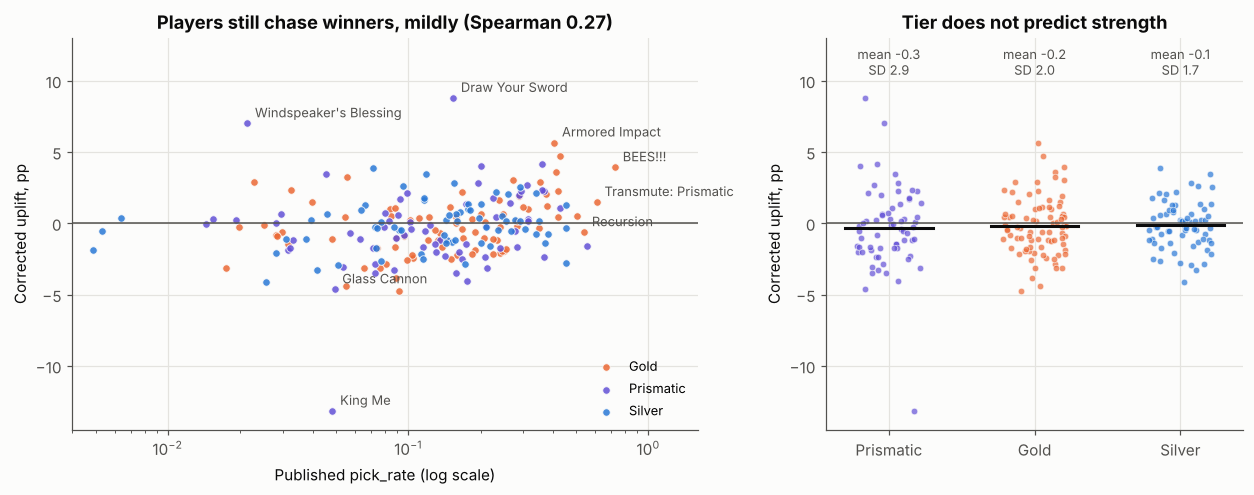

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
for t, g in A.groupby("tier"):
    ax.scatter(g.pick_rate, g.shrunk * 100, s=24, color=TIER[t], alpha=0.85, edgecolor=PAL["surface"], lw=0.6, label=t)
ax.axhline(0, color=PAL["ink2"], lw=1)
for nm in ["BEES!!!", "King Me", "Draw Your Sword", "Windspeaker's Blessing", "Recursion", "Armored Impact", "Glass Cannon", "Transmute: Prismatic"]:
    r = A[A.name == nm].iloc[0]
    ax.annotate(nm, (r.pick_rate, r.shrunk * 100), xytext=(5, 4), textcoords="offset points", fontsize=8.5, color=PAL["ink2"])
ax.set_xscale("log"); ax.set_xlim(0.004, 1.6); ax.set_ylim(-14.5, 13)
ax.set_xlabel("Published pick_rate (log scale)"); ax.set_ylabel("Corrected uplift, pp")
ax.set_title(f"Players still chase winners, mildly (Spearman {stats.spearmanr(A.pick_rate, A.shrunk)[0]:.2f})")
ax.legend(loc="lower right", fontsize=8.5)
ax = axes[1]
order = ["Prismatic", "Gold", "Silver"]
rng = np.random.default_rng(0)
for i, t in enumerate(order):
    g = A[A.tier == t].shrunk * 100
    ax.scatter(i + rng.uniform(-0.22, 0.22, len(g)), g, s=18, color=TIER[t], alpha=0.7, edgecolor=PAL["surface"], lw=0.5)
    ax.plot([i - 0.3, i + 0.3], [g.mean()] * 2, color=PAL["ink"], lw=2)
    ax.text(i, 10.2, f"mean {g.mean():+.1f}\nSD {g.std():.1f}", ha="center", va="bottom", fontsize=8.5, color=PAL["ink2"])
ax.axhline(0, color=PAL["ink2"], lw=1)
ax.set_xticks(range(3)); ax.set_xticklabels(order); ax.set_ylim(-14.5, 13)
ax.set_ylabel("Corrected uplift, pp")
ax.set_title("Tier does not predict strength")
fig.tight_layout(); save(fig, "fig4_popularity_and_tiers.png"); plt.show()

Two reversals relative to the published numbers. First, popularity and tier explained almost half of the published win rates (R^2 0.45, mostly the artifact); after correction log pick rate keeps a small positive coefficient (+0.5 pp per e-fold of pick rate) but the model explains little (R^2 0.15), and the picker mix (`E`) carries a coefficient above 1, so it behaves like a real baseline rather than noise. Second, tier differences vanish: Prismatic, Gold and Silver all average within half a point of zero. What differs is spread, and Prismatic's spread is two augments (Draw Your Sword at the top, King Me at the bottom).

The remaining pick-rate correlation (0.27) is the selection story the question anticipated, now at its true size: players take augments that fit, so a measured uplift is the uplift *among the games where someone chose it*, not the effect of forcing the augment on a random player. That bias cannot be removed with aggregate data, and it is why the corrected numbers should be read as "how good this augment is in the hands of the people who take it".

## 7. Champion-specific augments

The builds feed grades each augment S/A/B/C on each champion. The grade is undocumented, but it is not simply the pick order (within a champion and rarity the pick ranking and the grade disagree on 8% of pairs), and it tracks the augment's corrected uplift (Spearman 0.73 between an augment's share of S grades and its uplift). It is the only per-champion win signal available, so champion-specificity is measured as grade *polarisation*: an augment that is S on some champions and C on others.

In [14]:
G = L.pivot_table(index="augment_id", columns="grade", values="champion_id", aggfunc="count", fill_value=0)
G = G.div(G.sum(axis=1), axis=0)[["S", "A", "B", "C"]]
G["polar"] = np.minimum(G.S, G.C) * 2 + (G.S * G.C) ** 0.5     # high only when both tails are populated
G["n"] = L.groupby("augment_id").size()
G["name"] = G.index.map(NAME); G["tier"] = G.index.map(A.set_index("augment_id").tier); G["uplift"] = G.index.map(A.set_index("augment_id").shrunk)
G["n_pool"] = [sum(a in s for s in pool_ids.values()) for a in G.index]
print(f"Spearman(share of S grades, corrected uplift) = {stats.spearmanr(G.S, G.uplift)[0]:.2f}; Spearman(share of C, uplift) = {stats.spearmanr(G.C, G.uplift)[0]:.2f}")
# Within-champion pick share dispersion as a second, grade-free measure of specificity
cv = L.groupby("augment_id").p.agg(lambda x: x.std() / x.mean())
G["pick_cv"] = cv
print(f"Spearman(grade polarisation, pick-share dispersion across champions) = {stats.spearmanr(G.polar, G.pick_cv)[0]:.2f}")
spec = G[G.n >= 40].nlargest(12, "polar")
univ = G[G.n >= 150].nsmallest(6, "polar")
show = pd.concat([spec, univ])

# Who takes the polarised ones? name the three champions with the highest pick share for each.
best = L.sort_values("p", ascending=False).groupby("augment_id").head(3).groupby("augment_id").champion_id.apply(lambda s: ", ".join(CNAME[c] for c in s))
show = show.assign(top_pickers=show.index.map(best))
show[["name", "tier", "n", "S", "A", "B", "C", "uplift", "top_pickers"]].style.format({"S": "{:.0%}", "A": "{:.0%}", "B": "{:.0%}", "C": "{:.0%}", "uplift": "{:+.1%}"}).hide(axis="index")

Spearman(share of S grades, corrected uplift) = 0.73; Spearman(share of C, uplift) = -0.58
Spearman(grade polarisation, pick-share dispersion across champions) = 0.52


name,tier,n,S,A,B,C,uplift,top_pickers
Pressure Cooker,Gold,84,31%,27%,14%,27%,-1.7%,"Sion, Rell, Leona"
Dual Wield,Prismatic,97,34%,12%,28%,26%,+1.5%,"Vayne, Jinx, Yunara"
From Downtown,Gold,75,23%,28%,24%,25%,+0.5%,"Seraphine, Xerath, Ziggs"
Heavy Hitter,Silver,83,57%,18%,7%,18%,+2.6%,"DrMundo, Shen, Ornn"
Critical Rhythm,Gold,80,20%,25%,20%,35%,-1.0%,"Jinx, Tristana, Yunara"
Circle of Death,Prismatic,55,22%,25%,31%,22%,+1.7%,"DrMundo, Swain, Zac"
Purist - Caster,Silver,154,18%,24%,22%,36%,-1.4%,"Zilean, Teemo, Karthus"
Wooglet's Witchcap,Prismatic,106,44%,25%,13%,17%,+2.8%,"Xerath, Viktor, Syndra"
Upgrade Stormsurge,Gold,102,38%,25%,21%,16%,+0.6%,"Evelynn, Leblanc, Akali"
Steel Your Heart,Gold,85,52%,19%,15%,14%,+3.1%,"DrMundo, Rell, Ornn"


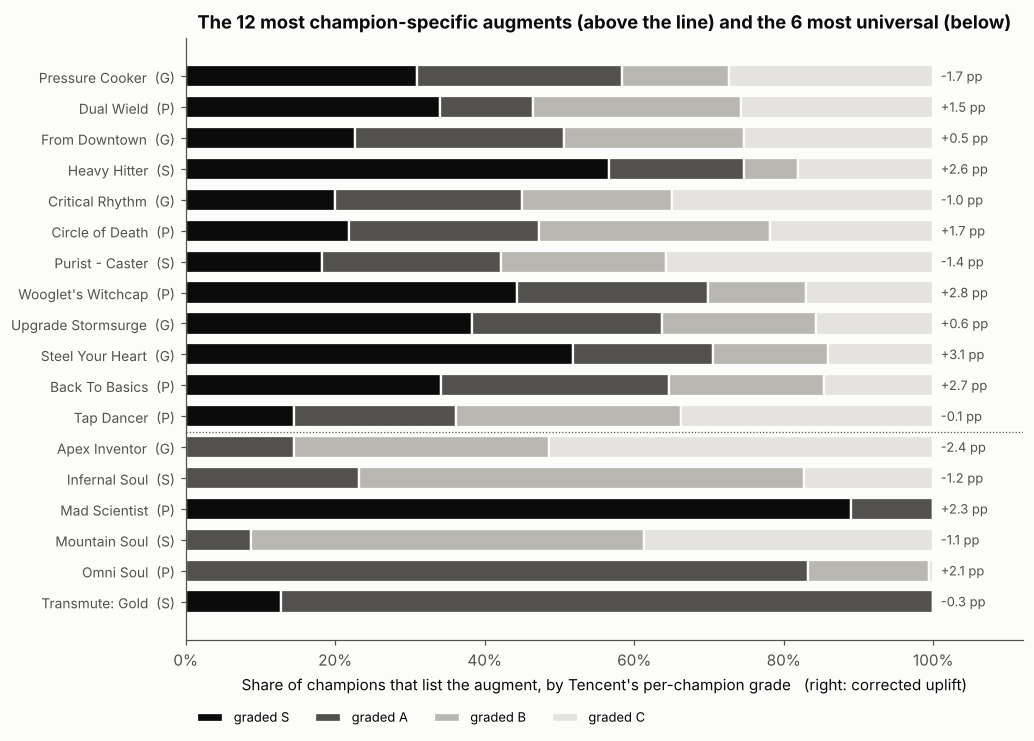

In [15]:
fig, ax = plt.subplots(figsize=(9.5, 6.8))
show = show.iloc[::-1]
y = np.arange(len(show))
left = np.zeros(len(show))
shade = {"S": PAL["ink"], "A": PAL["ink2"], "B": PAL["mute"], "C": PAL["grid"]}
for gcol in ["S", "A", "B", "C"]:
    ax.barh(y, show[gcol], left=left, color=shade[gcol], edgecolor=PAL["surface"], lw=1.5, label=f"graded {gcol}", height=0.72)
    left += show[gcol].values
for i, (_, r) in enumerate(show.iterrows()):
    ax.text(1.01, i, f"{r.uplift*100:+.1f} pp", va="center", fontsize=8.5, color=PAL["ink2"])
ax.set_yticks(y); ax.set_yticklabels([f"{n}  ({t[0]})" for n, t in zip(show.name, show.tier)], fontsize=9)
ax.axhline(5.5, color=PAL["ink2"], lw=0.8, ls=":")
ax.set_xlim(0, 1.12); ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Share of champions that list the augment, by Tencent's per-champion grade   (right: corrected uplift)")
ax.set_title("The 12 most champion-specific augments (above the line) and the 6 most universal (below)")
ax.legend(loc="lower left", ncol=4, fontsize=8.5, bbox_to_anchor=(0, -0.16))
ax.grid(False)
fig.tight_layout(); save(fig, "fig5_champion_specific.png"); plt.show()

The polarised augments are the ones whose value depends on a kit: Dual Wield and Critical Rhythm are S on Vayne and Jinx and C on casters, Heavy Hitter and Steel Your Heart are S on Dr. Mundo and Ornn, From Downtown wants artillery mages, Wooglet's Witchcap wants AP burst. The universal ones are flat stat buys (Mad Scientist, Omni Soul, Transmute: Gold) that get the same letter on almost everyone. Grade polarisation agrees with a grade-free measure, the dispersion of per-champion pick shares (Spearman 0.52 between the two), so it is not an artifact of how Tencent assigns letters.

## 8. Limitations

- **The game-level model is inferred, not documented.** Tencent does not describe its augment statistics. The model is supported by three independent checks (the pick-rate algebra in 2.2, the 50.3% mean after correction, the flat floor), and it has no free parameters, but a different mechanism that happens to produce the same curve cannot be ruled out. The correction assumes the two teams' augment draws are independent, which is only approximately true.
- **Offered vs picked.** Every number here is conditional on a player choosing the augment. The corrected uplift is the effect among the games where someone took it, which is what a player deciding between three cards needs, but it is not the causal effect of the augment on a random player.
- **Volume is estimated**, from the sibling notebook's lower bound of 80,000 games per day. Standard errors scale with its square root, so a 4x error in volume halves or doubles them; the test-retest check in Section 4 does not depend on it.
- **Per-champion win rates are not published**, so "who picks it" is handled through the composition baseline `E` and champion-specificity through Tencent's undocumented grade. The builds lists are truncated (93 to 157 of 214 augments per champion), which biases `implied` down for rare augments and leaves the long tail of each champion's picks unobserved.
- **One server, one week.** 16.21 had seven days of data when this ran; 31 augments (BEES!!! among them) are new this patch and have no earlier window to replicate against.

## 9. What the site should do

1. Replace the within-rarity linear detrend in `web/src/lib/augment-winrate.ts` with `w = win_rate x (1 - q/2)`, `q = 1 - sqrt(1 - pick_rate)`. It removes exactly the artifact and nothing else, needs no per-rarity re-centering, and the result is a team win rate the tier list can compare directly with champion win rates.
2. Show augments as uplift in percentage points with a sign, not as a win rate. "+3.9 pp" is the honest size of BEES!!!.
3. Keep the composition adjustment already in `augment-tiers.ts`; it is small but correct.
4. Re-run this notebook on each new patch window; `fig2` is the regression test.

## Reproduce

```
pip install -r analysis/augment-uplift/requirements.txt
cd analysis/augment-uplift
jupyter nbconvert --to notebook --execute --inplace augment-uplift.ipynb
```
Runs offline in under a minute from the files in `data/cn/` and `simulator/data/` and rewrites the five PNGs.